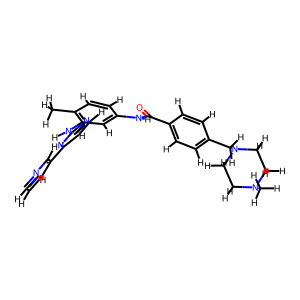

In [1]:
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import MolToImage

# Imatinib SMILES string from ChEMBL/PDB (Ligand ID: STI)
smiles = "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1"
molecule = Chem.MolFromSmiles(smiles)

# Prepare 3D coordinates
molecule = Chem.AddHs(molecule)
AllChem.EmbedMolecule(molecule, randomSeed=42)
AllChem.UFFOptimizeMolecule(molecule)

# Display 2D structure
display(MolToImage(molecule))

In [2]:
from pypdb import Query
import urllib.request
import biotite.database.rcsb as rcsb
import biotite.structure.io as bsio
from pathlib import Path
# Search for PDB entries containing the ligand ID 'STI' (Imatinib)
q = Query("STI", query_type="chemical")
pdb_ids = q.search()

print(f"Found {len(pdb_ids)} PDB structures containing Imatinib (STI):")
print(pdb_ids) # Print first 10 for brevity if the list is long

Found 29 PDB structures containing Imatinib (STI):
['1IEP', '1OPJ', '1T46', '1XBB', '2HYY', '2OIQ', '2PL0', '3FW1', '3GVU', '3HEC', '3K5V', '3MS9', '3MSS', '3OEZ', '3PYY', '4BKJ', '4CSV', '4R7I', '5MQT', '6HD4', '6HD6', '6JOL', '6KTN', '6NPE', '6NPU', '6NPV', '6VXH', '7N9G', '8S16']


In [3]:
import biotite.database.rcsb as rcsb
import biotite.structure.io as bsio
from tempfile import gettempdir

selected_pdb_ids = pdb_ids
print(f"Downloading structures for: {selected_pdb_ids}")

structures = {}
for pdb_id in selected_pdb_ids:
    try:
        # Passing gettempdir() forces fetch() to save to a file path instead of StringIO
        pdb_file = rcsb.fetch(pdb_id.lower(), "pdb", target_path=gettempdir())
        structures[pdb_id] = bsio.load_structure(pdb_file)
    except Exception as e:
        print(f"Could not load {pdb_id}: {e}")
        
print(f"Successfully loaded {len(structures)} structures into memory.")

Successfully loaded 29 structures into memory.


In [11]:
import biotite.structure as struc

ligands = {}
proteins = {}

for pdb_id, atom_array in structures.items():
    # Mask for the Imatinib ligand (residue name 'STI')
    ligand_mask = (atom_array.res_name == "STI")
    ligands[pdb_id] = atom_array[ligand_mask]
    
    # Mask for the protein atoms (excluding water and ligands)
    protein_mask = struc.filter_amino_acids(atom_array)
    proteins[pdb_id] = atom_array[protein_mask]
    
    print(f"{pdb_id}: Extracted ligand with {len(ligands[pdb_id])} atoms and protein with {len(proteins[pdb_id])} atoms.")

1IEP: Extracted ligand with 74 atoms and protein with 4458 atoms.
1OPJ: Extracted ligand with 74 atoms and protein with 4664 atoms.
1T46: Extracted ligand with 37 atoms and protein with 2359 atoms.
1XBB: Extracted ligand with 37 atoms and protein with 2112 atoms.
2HYY: Extracted ligand with 148 atoms and protein with 8354 atoms.
2OIQ: Extracted ligand with 37 atoms and protein with 4261 atoms.
2PL0: Extracted ligand with 37 atoms and protein with 2182 atoms.
3FW1: Extracted ligand with 68 atoms and protein with 3572 atoms.
3GVU: Extracted ligand with 74 atoms and protein with 2163 atoms.
3HEC: Extracted ligand with 37 atoms and protein with 2668 atoms.
3K5V: Extracted ligand with 74 atoms and protein with 4620 atoms.
3MS9: Extracted ligand with 74 atoms and protein with 4359 atoms.
3MSS: Extracted ligand with 148 atoms and protein with 8604 atoms.
3OEZ: Extracted ligand with 74 atoms and protein with 4203 atoms.
3PYY: Extracted ligand with 74 atoms and protein with 4223 atoms.
4BKJ: Ex

In [12]:
import biotite.structure as struc
import numpy as np

binding_sites = {}
cutoff_distance = 5.0 # Angstroms

for pdb_id in structures.keys():
    prot = proteins[pdb_id]
    lig = ligands[pdb_id]
    
    # Find protein atoms within the cutoff distance of any ligand atom
    # We can use biotite's distance search or cell list for efficiency, 
    # or a simple boolean mask using spatial distance
    cell_list = struc.CellList(prot, cell_size=cutoff_distance)
    # Find indices of protein atoms close to the ligand
    close_indices = cell_list.get_atoms(lig.coord, radius=cutoff_distance)
    # Flatten and unique the atom indices
    close_indices = set([idx for sublist in close_indices for idx in sublist])
    
    # Get the unique residue IDs belonging to those close atoms
    site_mask = np.zeros(len(prot), dtype=bool)
    site_mask[list(close_indices)] = True
    
    # Filter down to whole residues
    residue_ids = np.unique(prot.res_id[site_mask])
    res_mask = np.isin(prot.res_id, residue_ids)
    
    binding_sites[pdb_id] = prot[res_mask]
    print(f"{pdb_id}: Binding site isolated with {len(residues := np.unique(binding_sites[pdb_id].res_id))} residues.")

1IEP: Binding site isolated with 29 residues.
1OPJ: Binding site isolated with 31 residues.
1T46: Binding site isolated with 30 residues.
1XBB: Binding site isolated with 20 residues.
2HYY: Binding site isolated with 31 residues.
2OIQ: Binding site isolated with 29 residues.
2PL0: Binding site isolated with 27 residues.
3FW1: Binding site isolated with 12 residues.
3GVU: Binding site isolated with 44 residues.
3HEC: Binding site isolated with 25 residues.
3K5V: Binding site isolated with 30 residues.
3MS9: Binding site isolated with 29 residues.
3MSS: Binding site isolated with 29 residues.
3OEZ: Binding site isolated with 29 residues.
3PYY: Binding site isolated with 28 residues.
4BKJ: Binding site isolated with 30 residues.
4CSV: Binding site isolated with 28 residues.
4R7I: Binding site isolated with 27 residues.
5MQT: Binding site isolated with 24 residues.
6HD4: Binding site isolated with 30 residues.
6HD6: Binding site isolated with 29 residues.
6JOL: Binding site isolated with 2

In [13]:
import numpy as np

pdb_list = list(binding_sites.keys())
n_structs = len(pdb_list)
rmsd_matrix = np.full((n_structs, n_structs), np.nan)

print("\nCalculating pairwise RMSD matrix...")
for i in range(n_structs):
    for j in range(n_structs):
        if i == j:
            rmsd_matrix[i, j] = 0.0
            continue
        
        site_i = binding_sites[pdb_list[i]]
        site_j = binding_sites[pdb_list[j]]
        
        # Match lengths to ensure equal array shapes for superimposition
        min_len = min(len(site_i), len(site_j))
        sub_i = site_i[:min_len]
        sub_j = site_j[:min_len]
        
        # Perform structural superimposition and calculate RMSD
        fitted_j, transformation = struc.superimpose(sub_i, sub_j)
        calculated_rmsd = struc.rmsd(sub_i, fitted_j)
        
        rmsd_matrix[i, j] = calculated_rmsd
        print(f"RMSD ({pdb_list[i]} vs {pdb_list[j]}): {calculated_rmsd:.2f} Å")

print("\nRMSD calculation complete!")


Calculating pairwise RMSD matrix...
RMSD (1IEP vs 1OPJ): 16.98 Å
RMSD (1IEP vs 1T46): 7.22 Å
RMSD (1IEP vs 1XBB): 11.89 Å
RMSD (1IEP vs 2HYY): 16.72 Å
RMSD (1IEP vs 2OIQ): 15.38 Å
RMSD (1IEP vs 2PL0): 12.64 Å
RMSD (1IEP vs 3FW1): 10.07 Å
RMSD (1IEP vs 3GVU): 26.02 Å
RMSD (1IEP vs 3HEC): 12.40 Å
RMSD (1IEP vs 3K5V): 15.38 Å
RMSD (1IEP vs 3MS9): 3.84 Å
RMSD (1IEP vs 3MSS): 14.33 Å
RMSD (1IEP vs 3OEZ): 15.44 Å
RMSD (1IEP vs 3PYY): 20.66 Å
RMSD (1IEP vs 4BKJ): 16.79 Å
RMSD (1IEP vs 4CSV): 11.77 Å
RMSD (1IEP vs 4R7I): 12.01 Å
RMSD (1IEP vs 5MQT): 27.21 Å
RMSD (1IEP vs 6HD4): 15.40 Å
RMSD (1IEP vs 6HD6): 16.53 Å
RMSD (1IEP vs 6JOL): 12.15 Å
RMSD (1IEP vs 6KTN): 18.50 Å
RMSD (1IEP vs 6NPE): 21.09 Å
RMSD (1IEP vs 6NPU): 19.14 Å
RMSD (1IEP vs 6NPV): 21.54 Å
RMSD (1IEP vs 6VXH): 17.00 Å
RMSD (1IEP vs 7N9G): 27.31 Å
RMSD (1IEP vs 8S16): 21.20 Å
RMSD (1OPJ vs 1IEP): 16.98 Å
RMSD (1OPJ vs 1T46): 11.81 Å
RMSD (1OPJ vs 1XBB): 12.41 Å
RMSD (1OPJ vs 2HYY): 17.40 Å
RMSD (1OPJ vs 2OIQ): 16.43 Å
RMSD (1O

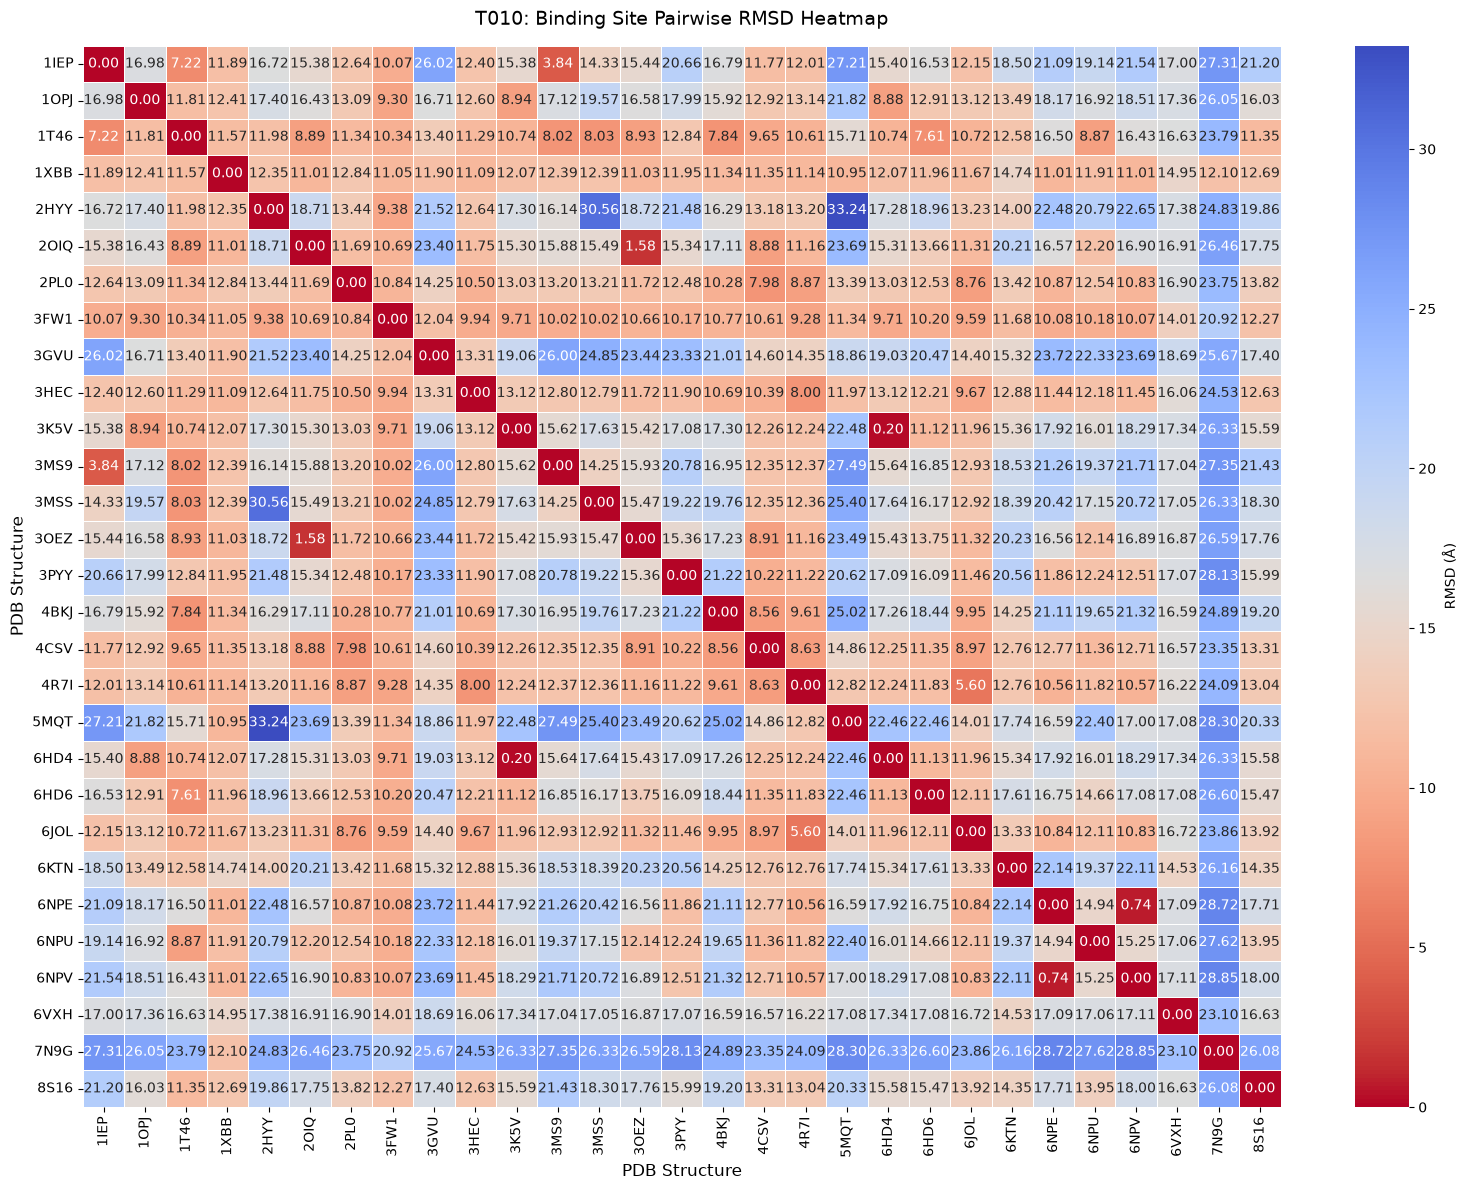

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert matrix to a DataFrame
df_rmsd = pd.DataFrame(rmsd_matrix, index=pdb_list, columns=pdb_list)

# Draw the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(
    df_rmsd, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm_r", 
    linewidths=0.5,
    cbar_kws={'label': 'RMSD (Å)'}
)

plt.title("T010: Binding Site Pairwise RMSD Heatmap", fontsize=14, pad=15)
plt.xlabel("PDB Structure", fontsize=12)
plt.ylabel("PDB Structure", fontsize=12)
plt.tight_layout()
plt.show()

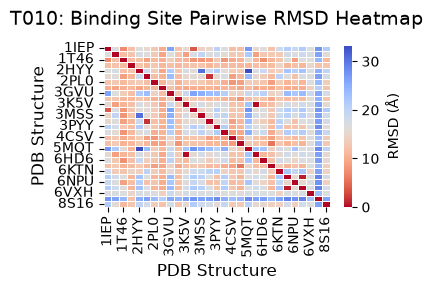

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert matrix to a DataFrame
df_rmsd = pd.DataFrame(rmsd_matrix, index=pdb_list, columns=pdb_list)

# Draw the heatmap
plt.figure(figsize=(4, 3))
sns.heatmap(
    df_rmsd, 
    cmap="coolwarm_r", 
    linewidths=0.5,
    cbar_kws={'label': 'RMSD (Å)'}
)

plt.title("T010: Binding Site Pairwise RMSD Heatmap", fontsize=14, pad=15)
plt.xlabel("PDB Structure", fontsize=12)
plt.ylabel("PDB Structure", fontsize=12)
plt.tight_layout()
plt.show()